In [ ]:
# Cau hinh ham do thoi gian va so nut duyet
import pandas as pd
import matplotlib.pyplot as plt
from scenarios import MapBuilder
from agents import SearchAgent

def run_benchmark(scenario_name: str, state, depths: list[int]):
    configs = [
        ("Minimax", False, False),
        ("Alpha-Beta", False, True),
        ("Heuristic Minimax", True, False),
        ("Heuristic Alpha-Beta", True, True)
    ]
    results = []

    for depth in depths:
        for name, use_h, use_ab in configs:
            agent = SearchAgent(player_id=1, max_depth=depth, 
                                use_heuristic=use_h, use_alpha_beta=use_ab)
            action = agent.get_action(state)
            results.append({
                "Scenario": scenario_name,
                "Algorithm": name,
                "Depth": depth,
                "Chosen Action": action.name,
                "Nodes Explored": agent.nodes_explored,
                "Time (ms)": round(agent.last_exec_time, 3)
            })
    return pd.DataFrame(results)


In [ ]:

# Chay thu nghiem tren 2 kich ban Endgame va Mid-game
df_endgame = run_benchmark("Endgame (1 HP)", MapBuilder.get_endgame_scenario(), depths=[2, 3, 4, 5])
df_midgame = run_benchmark("Mid-game (Full HP)", MapBuilder.get_midgame_scenario(), depths=[2, 3, 4, 5])

df_all = pd.concat([df_endgame, df_midgame], ignore_index=True)
display(df_all)


,Scenario,Algorithm,Depth,Chosen Action,Nodes Explored,Time (ms)
0,Endgame (1 HP),Minimax,2,MOVE_UP,42,0.462
1,Endgame (1 HP),Alpha-Beta,2,MOVE_UP,17,0.203
2,Endgame (1 HP),Heuristic Minimax,2,MOVE_RIGHT,42,0.513
3,Endgame (1 HP),Heuristic Alpha-Beta,2,MOVE_RIGHT,27,0.449
4,Endgame (1 HP),Minimax,3,MOVE_UP,240,1.891
5,Endgame (1 HP),Alpha-Beta,3,MOVE_UP,57,0.537
6,Endgame (1 HP),Heuristic Minimax,3,MOVE_RIGHT,240,2.045
7,Endgame (1 HP),Heuristic Alpha-Beta,3,MOVE_RIGHT,111,1.115
8,Endgame (1 HP),Minimax,4,MOVE_UP,1386,10.201
9,Endgame (1 HP),Alpha-Beta,4,MOVE_UP,126,1.813


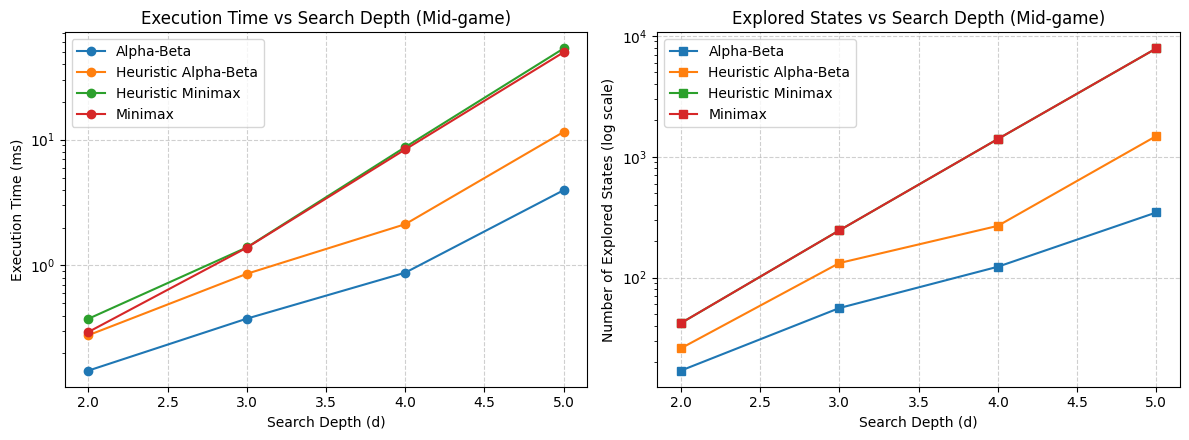

In [ ]:
# Ve bieu do log-scale so sanh 4 thuat toan
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for algo, group in df_midgame.groupby("Algorithm"):
    axes[0].plot(group["Depth"], group["Time (ms)"], marker='o', label=algo)
    axes[1].plot(group["Depth"], group["Nodes Explored"], marker='s', label=algo)

axes[0].set_title("Execution Time vs Search Depth (Mid-game)")
axes[0].set_xlabel("Search Depth (d)")
axes[0].set_ylabel("Execution Time (ms)")
axes[0].set_yscale("log")
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend()

axes[1].set_title("Explored States vs Search Depth (Mid-game)")
axes[1].set_xlabel("Search Depth (d)")
axes[1].set_ylabel("Number of Explored States (log scale)")
axes[1].set_yscale("log")
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.savefig("task2_benchmark.png", dpi=300)
plt.show()

In [ ]:
# Mo phong tran dau hoan chinh giua 2 thuat toan cho den khi co nguoi thang hoac het luot
def simulate_match(p1_config: tuple, p2_config: tuple, initial_state, max_turns: int = 120):
    p1_name, p1_h, p1_ab, p1_depth = p1_config
    p2_name, p2_h, p2_ab, p2_depth = p2_config

    # Khoi tao 2 agent dieu khien Tank 1 va Tank 2
    agent1 = SearchAgent(player_id=1, max_depth=p1_depth, use_heuristic=p1_h, use_alpha_beta=p1_ab)
    agent2 = SearchAgent(player_id=2, max_depth=p2_depth, use_heuristic=p2_h, use_alpha_beta=p2_ab)

    state = initial_state.clone()
    p1_times, p2_times = [], []
    p1_nodes, p2_nodes = [], []

    while not state.is_terminal(max_turns=max_turns):
        if state.current_turn == 1:
            action = agent1.get_action(state)
            p1_times.append(agent1.last_exec_time)
            p1_nodes.append(agent1.nodes_explored)
        else:
            action = agent2.get_action(state)
            p2_times.append(agent2.last_exec_time)
            p2_nodes.append(agent2.nodes_explored)

        state = state.apply_action(action)

    # Kiem tra ket qua thang thua dua tren gia tri utility cuoi tran
    util = state.get_utility(max_player=1)
    if util > 0:
        winner = f"P1 ({p1_name})"
    elif util < 0:
        winner = f"P2 ({p2_name})"
    else:
        winner = "Draw (Timeout)"

    return {
        "Matchup": f"{p1_name} (d={p1_depth}) vs {p2_name} (d={p2_depth})",
        "Winner": winner,
        "Total Turns": state.turn_count,
        "P1 HP (Tank/Base)": f"{state.tanks[1].hp}/{state.bases[1].hp}",
        "P2 HP (Tank/Base)": f"{state.tanks[2].hp}/{state.bases[2].hp}",
        "P1 Avg Time (ms)": round(sum(p1_times) / max(1, len(p1_times)), 2),
        "P2 Avg Time (ms)": round(sum(p2_times) / max(1, len(p2_times)), 2),
        "P1 Avg Nodes": int(sum(p1_nodes) / max(1, len(p1_nodes))),
        "P2 Avg Nodes": int(sum(p2_nodes) / max(1, len(p2_nodes)))
    }

# Danh sach cac cap dau thu nghiem tren ban do Battle City va Mid-game
matchups = [
    # Cap 1: Heuristic Alpha-Beta dau voi Alpha-Beta thuan (Khong co Heuristic)
    (("Heuristic AB", True, True, 4), ("Pure AB", False, True, 4), MapBuilder.get_midgame_scenario()),
    # Cap 2: Heuristic Alpha-Beta (d=4) dau voi Heuristic Minimax (d=3) de thay loi the do sau
    (("Heuristic AB", True, True, 4), ("Heuristic MM", True, False, 3), MapBuilder.get_midgame_scenario()),
    # Cap 3: Tran dau tren ban do Battle City 13x13
    (("Heuristic AB", True, True, 4), ("Pure MM", False, False, 3), MapBuilder.get_battle_city_map())
]

tournament_results = [simulate_match(p1, p2, st) for p1, p2, st in matchups]
df_tournament = pd.DataFrame(tournament_results)
display(df_tournament)